# What Moves Bitcoin? A Two-Year Look at Stocks, AI, Oil, Gold, the Dollar and Interest Rates

**Author:** Serhii Popeliuk  |  **Tools:** Python (pandas, matplotlib, seaborn), Excel, Tableau

## 1. The question
> **What has moved Bitcoin's price over the last 2 years: stocks, AI/tech, oil, gold, the dollar, or interest rates? And has that relationship changed over time?**

## 2. Why it matters
Bitcoin is sold as "digital gold", but it is often traded like a risk asset. If it behaves like tech stocks, it gives an investor little diversification. If it behaves like gold, it can act as a hedge. The answer may also change with the market regime, so I test whether it did.

## 3. Scope and approach
| Step | What I do |
|---|---|
| Data | Daily prices for Bitcoin and 9 market factors, pulled from Yahoo Finance via `yfinance` |
| Proxies | Stocks = S&P 500 and Nasdaq; AI/tech = Nvidia and a semiconductor ETF; oil = WTI futures; gold = gold futures; dollar = US Dollar Index; rates = 10-year Treasury yield; fear = VIX |
| Methods | Daily returns, correlations, rolling correlations, first-half vs second-half comparison, a standardised regression, and a small event study |
| Out of scope | Population trends (too slow-moving for daily data) and causal claims. This is an association study. |

> **Disclaimer:** This is an educational analysis, not investment advice. Correlation is not causation.

## 4. Setup

In [35]:
import warnings
warnings.filterwarnings("ignore")

from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)

# ---- Configuration -------------------------------------------------------
END = pd.Timestamp(date.today())
START = END - pd.DateOffset(years=2)

# Yahoo Finance ticker -> readable name
TICKERS = {
    "BTC-USD":   "Bitcoin",
    "^GSPC":     "S&P 500",
    "^IXIC":     "Nasdaq",
    "NVDA":      "Nvidia",
    "SOXX":      "Semiconductor ETF",
    "CL=F":      "Oil (WTI)",
    "GC=F":      "Gold",
    "DX-Y.NYB":  "US Dollar Index",
    "^VIX":      "VIX",
    "^TNX":      "10Y Yield",
}
LEVEL_DIFF = ["10Y Yield"]   # a yield is a rate, so I use its daily change, not a % return
WINDOW = 90                  # rolling-correlation window (trading days)

RAW_FILE = Path("data/raw/prices_raw.csv")
PROCESSED = Path("data/processed")
IMAGES = Path("images")
for p in (RAW_FILE.parent, PROCESSED, IMAGES):
    p.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print(f"Analysis window: {START.date()} to {END.date()}")

Analysis window: 2024-10-09 to 2026-10-09


## 5. Load and check the data
The first run downloads the data and caches it in `data/raw/prices_raw.csv`. Later runs read the cache so the results are reproducible. Delete the file to refresh the data.

In [36]:
if RAW_FILE.exists():
    raw = pd.read_csv(RAW_FILE, index_col=0, parse_dates=True)
    print("Loaded cached data from", RAW_FILE)
else:
    import yfinance as yf
    raw = yf.download(
        list(TICKERS),
        start=START.strftime("%Y-%m-%d"),
        end=(END + pd.Timedelta(days=1)).strftime("%Y-%m-%d"),
        auto_adjust=True,
        progress=False,
    )["Close"]
    raw.to_csv(RAW_FILE)
    print("Downloaded fresh data and saved to", RAW_FILE)

raw.index = pd.to_datetime(raw.index)
if getattr(raw.index, "tz", None) is not None:
    raw.index = raw.index.tz_localize(None)

print(raw.shape)
raw.head()

Loaded cached data from data/raw/prices_raw.csv
(731, 10)


,BTC-USD,CL=F,DX-Y.NYB,GC=F,NVDA,SOXX,^GSPC,^IXIC,^TNX,^VIX
Date,,,,,,,,,,
2024-10-09,60582.101562,73.239998,102.930000,2626.000000,132.295044,232.728714,5792.040039,18291.619141,4.067,20.860001
2024-10-10,60274.500000,75.849998,102.989998,2639.300049,134.449249,231.095718,5780.049805,18282.050781,4.096,20.930000
2024-10-11,62445.089844,75.559998,102.889999,2676.300049,134.439285,233.035522,5815.029785,18342.939453,4.073,20.459999
2024-10-12,63193.023438,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-10-13,62851.375000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [37]:
raw.info()
print()
print("Missing values per column:")
print(raw.isna().sum())

<class 'pandas.DataFrame'>
DatetimeIndex: 731 entries, 2024-10-09 to 2026-10-09
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   BTC-USD   731 non-null    float64
 1   CL=F      504 non-null    float64
 2   DX-Y.NYB  504 non-null    float64
 3   GC=F      504 non-null    float64
 4   NVDA      502 non-null    float64
 5   SOXX      502 non-null    float64
 6   ^GSPC     502 non-null    float64
 7   ^IXIC     502 non-null    float64
 8   ^TNX      502 non-null    float64
 9   ^VIX      504 non-null    float64
dtypes: float64(10)
memory usage: 62.8 KB

Missing values per column:
BTC-USD       0
CL=F        227
DX-Y.NYB    227
GC=F        227
NVDA        229
SOXX        229
^GSPC       229
^IXIC       229
^TNX        229
^VIX        227
dtype: int64


**What I check here:** Bitcoin trades 7 days a week, while stocks, gold, and oil only trade on business days. This is why some columns have more missing values than others, and why the cleaning step has to put everything on one calendar.

## 6. Clean and tidy
Decisions:
1. Rename tickers to readable names and sort by date.
2. Use **US stock-market trading days** as the common calendar. Bitcoin's weekend moves are captured in Monday's return.
3. Forward-fill gaps of up to 3 days (holidays in some markets), then drop any remaining incomplete rows.
4. Convert prices to **log returns**. For the 10-year yield, use the **daily change in percentage points**.

In [38]:
prices = raw.sort_index().rename(columns=TICKERS)[list(TICKERS.values())]
prices.index.name = "Date"

trading_days = prices["S&P 500"].dropna().index
before = len(prices)
prices = prices.ffill(limit=3).loc[trading_days].dropna()
print(f"Rows before: {before}  |  after aligning to trading days: {len(prices)}")

# Returns
returns = np.log(prices.drop(columns=LEVEL_DIFF)).diff()
returns["10Y Yield (chg)"] = prices["10Y Yield"].diff()
returns = returns.replace([np.inf, -np.inf], np.nan).dropna()

print(f"Final dataset: {prices.index.min().date()} to {prices.index.max().date()}  ({len(returns)} daily returns)")
prices.tail()

Rows before: 731  |  after aligning to trading days: 502
Final dataset: 2024-10-09 to 2026-10-09  (501 daily returns)


,Bitcoin,S&P 500,Nasdaq,Nvidia,Semiconductor ETF,Oil (WTI),Gold,US Dollar Index,VIX,10Y Yield
Date,,,,,,,,,,
2026-10-05,85786.593750,7773.950195,27477.310547,238.899994,589.510010,89.430000,4156.799805,102.169998,15.52,5.311
2026-10-06,85557.562500,7818.930176,27599.789062,239.240005,589.450012,89.440002,4187.100098,101.830002,15.01,5.269
2026-10-07,83275.929688,7801.770020,27538.689453,237.470001,582.820007,88.279999,4140.700195,102.239998,15.08,5.277
2026-10-08,81676.335938,7765.359863,27193.339844,230.479996,563.280029,91.489998,4157.000000,102.139999,15.41,5.231
2026-10-09,82411.578125,7816.759766,27374.376953,229.729904,559.880005,90.930000,4224.200195,102.203003,14.88,5.240


## 7. Explore and describe

### 7.1 Summary statistics

In [39]:
price_assets = prices.drop(columns=LEVEL_DIFF)
drawdown = price_assets / price_assets.cummax() - 1

summary = pd.DataFrame({
    "Total return %":      (price_assets.iloc[-1] / price_assets.iloc[0] - 1) * 100,
    "Annualised vol %":    returns[price_assets.columns].std() * np.sqrt(252) * 100,
    "Max drawdown %":      drawdown.min() * 100,
    "Current drawdown %":  drawdown.iloc[-1] * 100,
}).round(1)
summary.sort_values("Total return %", ascending=False)

,Total return %,Annualised vol %,Max drawdown %,Current drawdown %
Semiconductor ETF,140.6,42.4,-35.2,-14.5
Nvidia,73.6,44.0,-36.9,-4.0
Gold,60.9,24.6,-24.9,-20.6
Nasdaq,49.7,21.5,-24.3,-0.8
Bitcoin,36.0,43.9,-53.1,-33.9
S&P 500,35.0,16.0,-18.9,-0.0
Oil (WTI),24.2,45.8,-39.3,-19.5
US Dollar Index,-0.7,6.7,-12.5,-7.1
VIX,-28.7,132.9,-74.3,-71.6


**Reading the table:** *Max drawdown* is the worst peak-to-trough fall in the window. *Current drawdown* shows how far each asset is from its own peak today, which speaks to the "some never recovered, some are recovering" question.

### 7.2 Everything on one scale (rebased to 100)

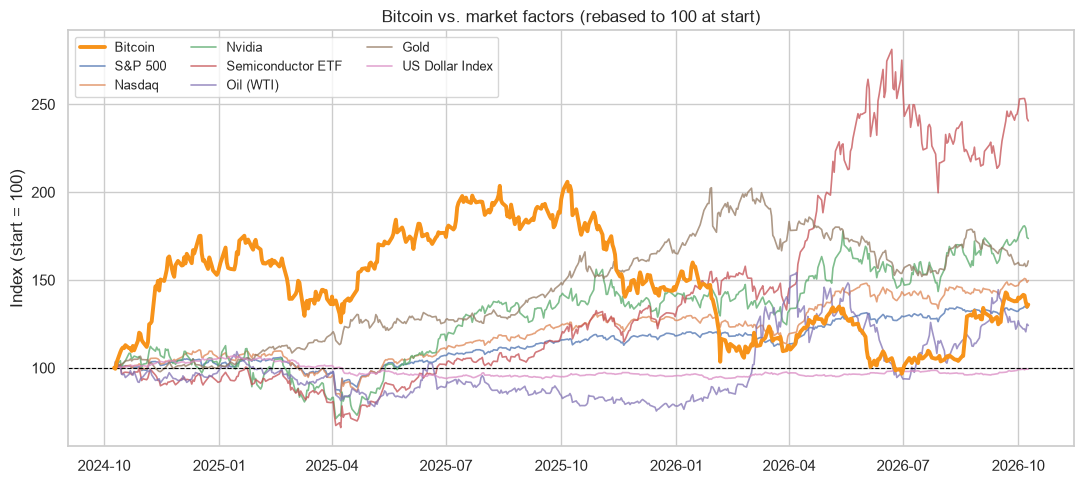

In [40]:
rebased = price_assets.drop(columns=["VIX"]) / price_assets.drop(columns=["VIX"]).iloc[0] * 100

fig, ax = plt.subplots()
for col in rebased.columns:
    if col == "Bitcoin":
        ax.plot(rebased.index, rebased[col], color="#F7931A", linewidth=2.8, label=col, zorder=5)
    else:
        ax.plot(rebased.index, rebased[col], linewidth=1.2, alpha=0.75, label=col)
ax.axhline(100, color="black", linewidth=0.8, linestyle="--")
ax.set_title("Bitcoin vs. market factors (rebased to 100 at start)")
ax.set_ylabel("Index (start = 100)")
ax.legend(ncol=3, fontsize=9)
save_fig("01_rebased_prices")

### 7.3 Drawdowns: how deep did each asset fall from its peak?

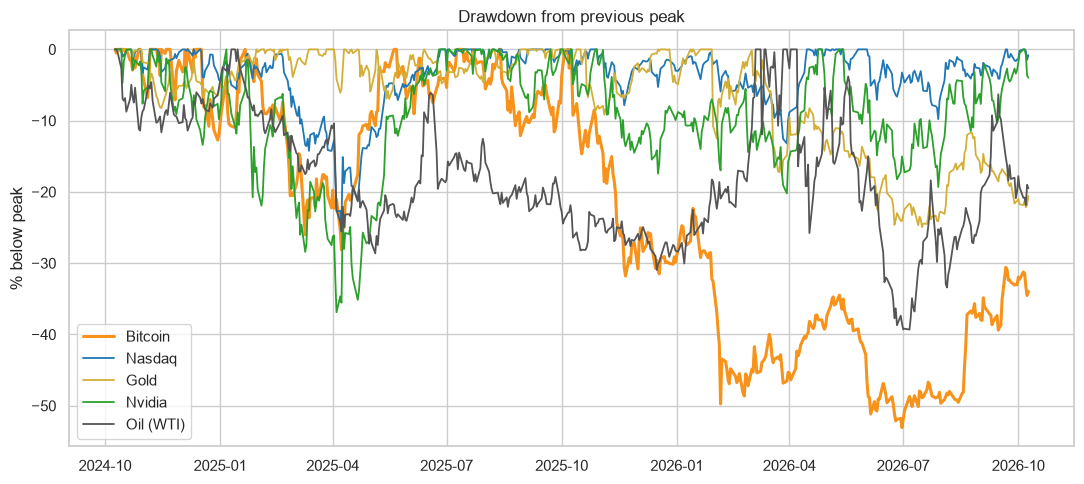

In [41]:
fig, ax = plt.subplots()
for col, color in [("Bitcoin", "#F7931A"), ("Nasdaq", "#1f77b4"), ("Gold", "#d4af37"), ("Nvidia", "#2ca02c"), ("Oil (WTI)", "#555555")]:
    ax.plot(drawdown.index, drawdown[col] * 100, label=col, color=color, linewidth=2.2 if col == "Bitcoin" else 1.3)
ax.set_title("Drawdown from previous peak")
ax.set_ylabel("% below peak")
ax.legend()
save_fig("02_drawdowns")

### 7.4 Correlation of daily returns

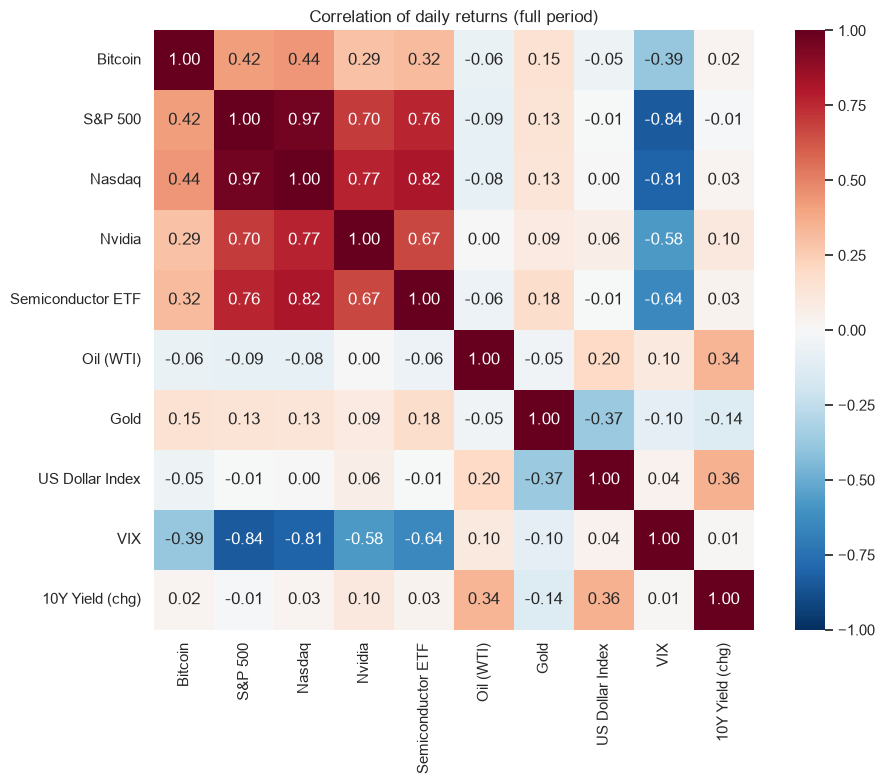

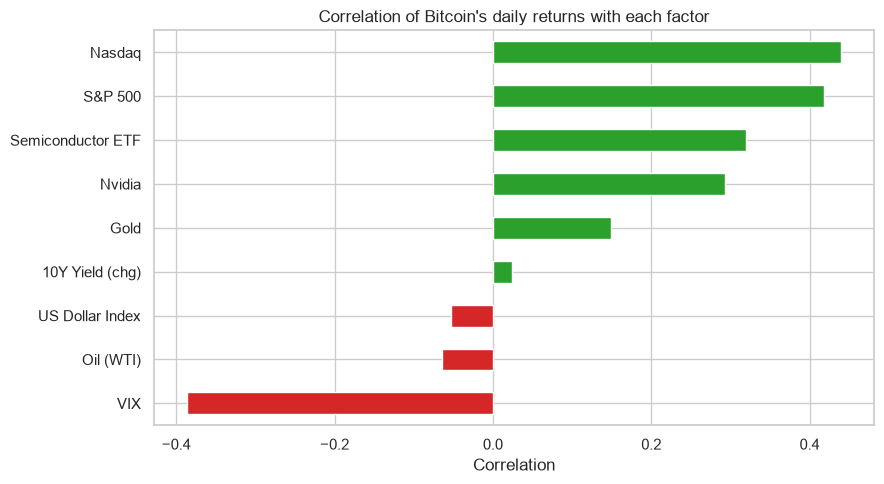

Nasdaq               0.44
S&P 500              0.42
Semiconductor ETF    0.32
Nvidia               0.29
Gold                 0.15
10Y Yield (chg)      0.02
US Dollar Index     -0.05
Oil (WTI)           -0.06
VIX                 -0.39
Name: Bitcoin, dtype: float64

In [42]:
corr = returns.corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlation of daily returns (full period)")
save_fig("03_correlation_heatmap")

btc_corr = corr["Bitcoin"].drop("Bitcoin").sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
btc_corr.plot(kind="barh", color=["#d62728" if v < 0 else "#2ca02c" for v in btc_corr], ax=ax)
ax.set_title("Correlation of Bitcoin's daily returns with each factor")
ax.set_xlabel("Correlation")
save_fig("04_btc_correlation_bars")
btc_corr.round(2).sort_values(ascending=False)

**Watch out:** Nasdaq, S&P 500, Nvidia and the semiconductor ETF are highly correlated with each other. They are all measuring "the stock market". I keep them in the correlation view, but avoid putting them all into the regression together.

## 8. Has the relationship changed over time?
### 8.1 Rolling correlation
A 90-trading-day window slides across the data. A line that moves up or down shows Bitcoin behaving more or less like that asset.

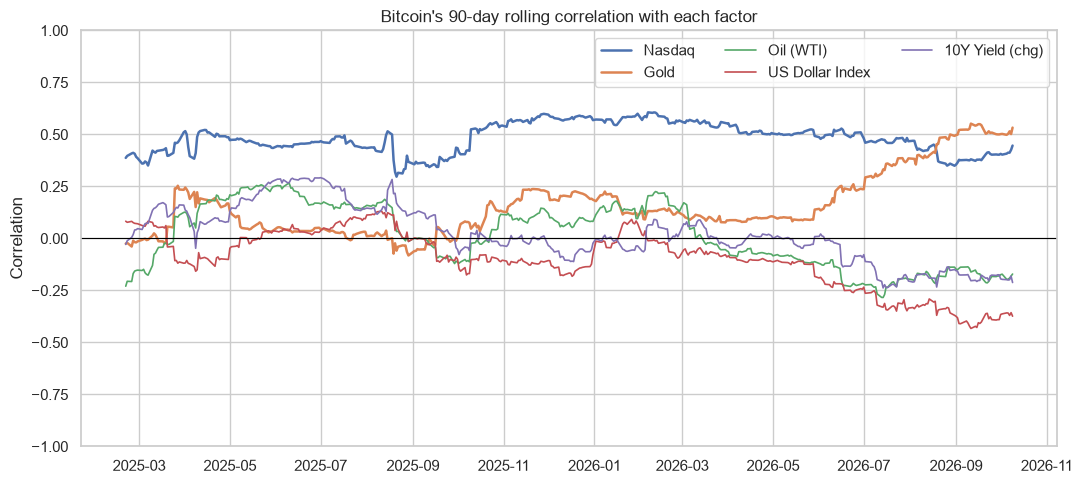

In [43]:
factors = [c for c in returns.columns if c != "Bitcoin"]
rolling_corr = pd.DataFrame({
    f: returns["Bitcoin"].rolling(WINDOW).corr(returns[f]) for f in factors
}).dropna()

show = ["Nasdaq", "Gold", "Oil (WTI)", "US Dollar Index", "10Y Yield (chg)"]
fig, ax = plt.subplots()
for f in show:
    ax.plot(rolling_corr.index, rolling_corr[f], label=f, linewidth=1.8 if f in ("Nasdaq", "Gold") else 1.2)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylim(-1, 1)
ax.set_title(f"Bitcoin's {WINDOW}-day rolling correlation with each factor")
ax.set_ylabel("Correlation")
ax.legend(ncol=3)
save_fig("05_rolling_correlation")

### 8.2 First half vs. second half of the period

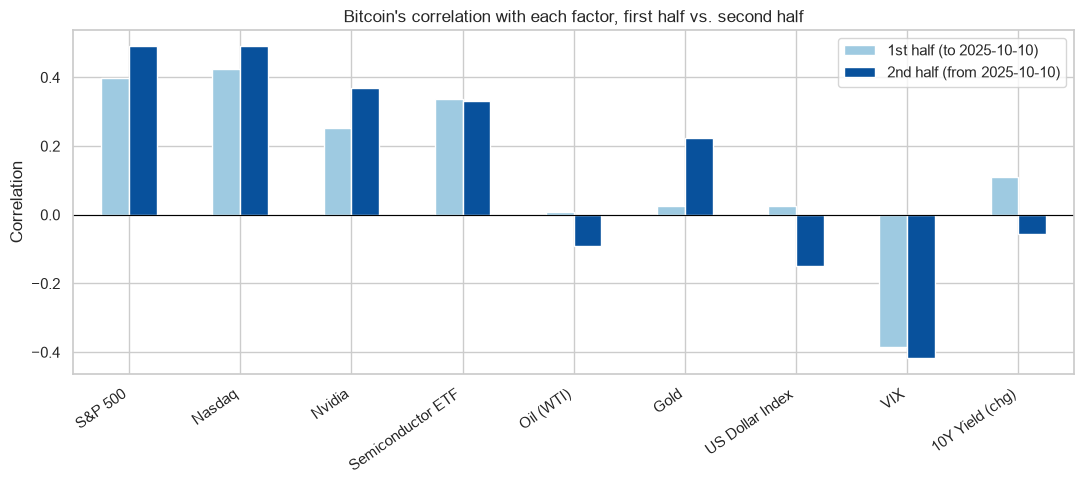

,1st half (to 2025-10-10),2nd half (from 2025-10-10),Change
Gold,0.03,0.22,0.20
Nvidia,0.25,0.37,0.12
S&P 500,0.40,0.49,0.09
Nasdaq,0.42,0.49,0.07
Semiconductor ETF,0.34,0.33,-0.00
VIX,-0.38,-0.42,-0.03
Oil (WTI),0.01,-0.09,-0.10
10Y Yield (chg),0.11,-0.06,-0.17
US Dollar Index,0.03,-0.15,-0.18


In [44]:
mid = returns.index[len(returns) // 2]
first, second = returns.loc[:mid], returns.loc[mid:]

compare = pd.DataFrame({
    f"1st half (to {mid.date()})": first.corr()["Bitcoin"],
    f"2nd half (from {mid.date()})": second.corr()["Bitcoin"],
}).drop("Bitcoin")
compare["Change"] = compare.iloc[:, 1] - compare.iloc[:, 0]

compare.iloc[:, :2].plot(kind="bar", figsize=(11, 5), color=["#9ecae1", "#08519c"])
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Bitcoin's correlation with each factor, first half vs. second half")
plt.ylabel("Correlation")
plt.xticks(rotation=35, ha="right")
save_fig("06_half_comparison")
compare.round(2).sort_values("Change", ascending=False)

## 9. Which factors matter most together? (Standardised regression)
Correlation looks at one factor at a time. A regression looks at them together. All variables are standardised (mean 0, std 1), so each coefficient reads as *"a 1-standard-deviation move in this factor goes with a X-standard-deviation move in Bitcoin"*, and the coefficients can be compared directly.

To limit overlap, I use one stock-market proxy (**Nasdaq**, which is tech-heavy) plus gold, oil, the dollar and the yield change.

In [45]:
REG_FACTORS = ["Nasdaq", "Gold", "Oil (WTI)", "US Dollar Index", "10Y Yield (chg)"]

def ols(df):
    z = (df[["Bitcoin"] + REG_FACTORS] - df[["Bitcoin"] + REG_FACTORS].mean()) / df[["Bitcoin"] + REG_FACTORS].std()
    y = z["Bitcoin"].values
    X = np.column_stack([np.ones(len(z)), z[REG_FACTORS].values])
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    resid = y - X @ beta
    n, k = X.shape
    cov = (resid @ resid / (n - k)) * np.linalg.inv(X.T @ X)
    t = beta / np.sqrt(np.diag(cov))
    r2 = 1 - (resid @ resid) / (y @ y)
    return pd.DataFrame({"coef": beta[1:], "t-stat": t[1:]}, index=REG_FACTORS), r2

res_full, r2_full = ols(returns)
res_1, r2_1 = ols(first)
res_2, r2_2 = ols(second)

reg_table = pd.concat({
    "Full period": res_full, "1st half": res_1, "2nd half": res_2
}, axis=1).round(2)
print(f"R-squared  |  full: {r2_full:.2f}   1st half: {r2_1:.2f}   2nd half: {r2_2:.2f}")
reg_table

R-squared  |  full: 0.20   1st half: 0.19   2nd half: 0.26


Full period        1st half        2nd half       
                       coef t-stat     coef t-stat     coef t-stat
Nasdaq                 0.42  10.43     0.44   7.41     0.49   8.09
Gold                   0.09   1.98     0.07   0.98     0.10   1.64
Oil (WTI)             -0.04  -0.85    -0.13  -1.94     0.05   0.82
US Dollar Index       -0.03  -0.69    -0.01  -0.11    -0.02  -0.37
10Y Yield (chg)        0.05   1.08     0.07   1.11     0.06   0.99

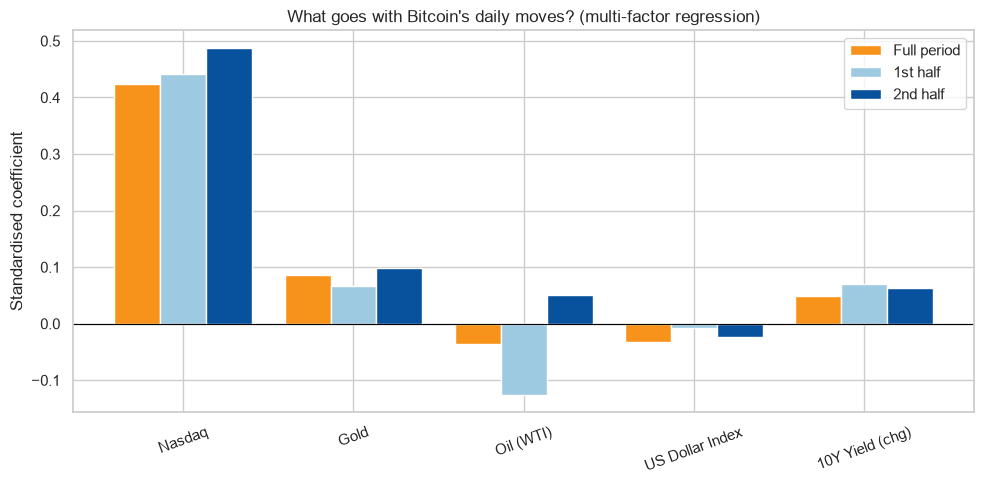

In [46]:
fig, ax = plt.subplots(figsize=(10, 5))
width = 0.27
x = np.arange(len(REG_FACTORS))
ax.bar(x - width, res_full["coef"], width, label="Full period", color="#F7931A")
ax.bar(x,         res_1["coef"],    width, label="1st half",    color="#9ecae1")
ax.bar(x + width, res_2["coef"],    width, label="2nd half",    color="#08519c")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(REG_FACTORS, rotation=20)
ax.set_ylabel("Standardised coefficient")
ax.set_title("What goes with Bitcoin's daily moves? (multi-factor regression)")
ax.legend()
save_fig("07_regression_coefficients")

**How to read it:** a |t-stat| above about 2 suggests the coefficient is distinguishable from zero. These are plain OLS standard errors on daily returns, so they are indicative, not definitive. A low R-squared means most of Bitcoin's daily movement is **not** explained by these factors, which is a finding in itself.

## 10. Event study: politics and macro moments
I test a handful of dated events and compare Bitcoin's move from the close **before** the event to **5 trading days after** with Nasdaq and gold over the same window.



In [47]:
EVENTS = {
    "2024-11-05": "US election",
    "2024-12-18": "Fed meeting (rate cut, cautious outlook)",
    "2025-01-20": "US administration change",
    "2025-04-02": "US trade policy announcement",
}
AFTER_DAYS = 5

rows = []
for d, label in EVENTS.items():
    d = pd.Timestamp(d)
    i = prices.index.searchsorted(d)
    if i < 1 or i + AFTER_DAYS >= len(prices):
        continue  # event falls outside my data window
    base, end = prices.iloc[i - 1], prices.iloc[i + AFTER_DAYS]
    rows.append({
        "Event": label, "Date": d.date(),
        "Bitcoin %": (end["Bitcoin"] / base["Bitcoin"] - 1) * 100,
        "Nasdaq %":  (end["Nasdaq"]  / base["Nasdaq"]  - 1) * 100,
        "Gold %":    (end["Gold"]    / base["Gold"]    - 1) * 100,
    })

events_df = pd.DataFrame(rows).round(1)
events_df

,Event,Date,Bitcoin %,Nasdaq %,Gold %
0,US election,2024-11-05,29.7,6.1,-5.1
1,"Fed meeting (rate cut, cautious outlook)",2024-12-18,-9.7,-0.4,-0.3
2,US administration change,2025-01-20,-3.0,0.5,0.7
3,US trade policy announcement,2025-04-02,-3.0,-1.9,-2.1


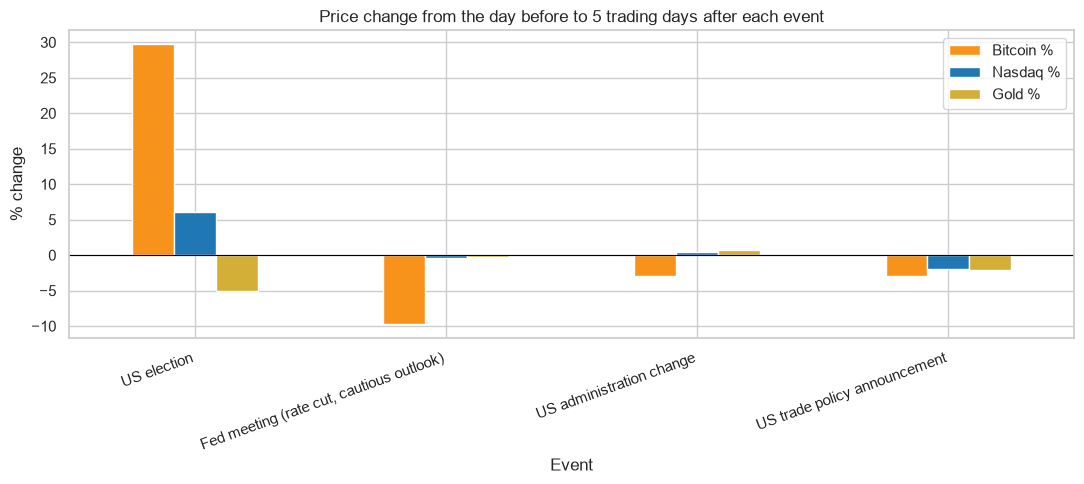

In [48]:
if len(events_df):
    events_df.set_index("Event")[["Bitcoin %", "Nasdaq %", "Gold %"]].plot(
        kind="bar", figsize=(11, 5), color=["#F7931A", "#1f77b4", "#d4af37"])
    plt.axhline(0, color="black", linewidth=0.8)
    plt.title(f"Price change from the day before to {AFTER_DAYS} trading days after each event")
    plt.ylabel("% change")
    plt.xticks(rotation=20, ha="right")
    save_fig("08_event_study")
else:
    print("No events fall inside the data window.")

## 11. Findings
The cell below writes its sentences from the computed results, so the numbers always match the data.

In [49]:
full_corr = returns.corr()["Bitcoin"].drop("Bitcoin")
top = full_corr.abs().sort_values(ascending=False).index[0]
change = compare["Change"]
biggest_shift = change.abs().sort_values(ascending=False).index[0]
nas_roll = rolling_corr["Nasdaq"]
gold_roll = rolling_corr["Gold"]
sig = res_full.index[res_full["t-stat"].abs() > 2].tolist()

print(f"1. Over the full period, Bitcoin's daily returns were most strongly linked to {top} (correlation {full_corr[top]:.2f}).")
print(f"2. Bitcoin's correlation with the Nasdaq averaged {nas_roll.mean():.2f} (range {nas_roll.min():.2f} to {nas_roll.max():.2f}), "
      f"versus {gold_roll.mean():.2f} for gold (range {gold_roll.min():.2f} to {gold_roll.max():.2f}).")
print(f"3. The relationship that changed most between the two halves was {biggest_shift}: "
      f"{compare.loc[biggest_shift].iloc[0]:.2f} -> {compare.loc[biggest_shift].iloc[1]:.2f}.")
print(f"4. In the multi-factor regression, factors with |t| > 2 over the full period: {', '.join(sig) if sig else 'none'}. "
      f"Together they explain {r2_full:.0%} of Bitcoin's daily variance.")
print(f"5. Bitcoin's current drawdown from its own peak is {summary.loc['Bitcoin', 'Current drawdown %']:.1f}%, "
      f"compared with {summary.loc['Nasdaq', 'Current drawdown %']:.1f}% for the Nasdaq and {summary.loc['Gold', 'Current drawdown %']:.1f}% for gold.")

1. Over the full period, Bitcoin's daily returns were most strongly linked to Nasdaq (correlation 0.44).
2. Bitcoin's correlation with the Nasdaq averaged 0.48 (range 0.30 to 0.61), versus 0.16 for gold (range -0.08 to 0.55).
3. The relationship that changed most between the two halves was Gold: 0.03 -> 0.22.
4. In the multi-factor regression, factors with |t| > 2 over the full period: Nasdaq. Together they explain 20% of Bitcoin's daily variance.
5. Bitcoin's current drawdown from its own peak is -33.9%, compared with -0.8% for the Nasdaq and -20.6% for gold.


### My takeaway 
- **One-sentence answer:** Over the past two years, Bitcoin's daily moves were most closely tied to the Nasdaq (correlation 0.44, and 0.30 to 0.61 on a rolling basis), while its link to gold was much weaker (average 0.16), so Bitcoin behaved more like a tech-driven risk asset than like digital gold.
- **What surprised me:** Bitcoin's correlation with gold rose from 0.03 in the first half to 0.22 in the second, one of the largest shifts, similar in size to the US dollar and the 10-year yield moving the other way. The 90-day rolling correlation with gold even peaked at 0.55. In the regression, however, the Nasdaq was the only clearly significant factor (gold was borderline, t = 1.98), and all factors together explained only 20% of Bitcoin's daily variance.
- **What I would tell an investor:** Bitcoin did not offer much protection against tech-stock swings in this period, and it is currently about 34% below its own peak, while the Nasdaq is almost at its high (-0.8%). Treat it as a high-risk asset that moves with the market rather than as a safe haven, and note that most of its daily movement is driven by things these factors don't capture.

### Limitations
- Correlation and regression show **association, not causation**.
- Two years of data covers one market regime; results may differ in other periods.
- Daily returns are noisy, and plain OLS errors ignore autocorrelation and changing volatility.
- Political and AI effects are proxied by markets and a short, hand-picked event list. Real causes are harder to isolate.
- Population and demographic trends are not tested because they move on a timescale of decades.

### Next steps
- Add macro data from FRED (Fed funds rate, CPI) and test inflation surprises.
- Test lead/lag relationships (does Nasdaq today predict Bitcoin tomorrow?).
- Add Ethereum and other coins to see whether the pattern is Bitcoin-specific.

## 12. Export for Excel and Tableau
Tidy files are saved so the same data can drive a Tableau dashboard and an Excel workbook.

In [50]:
prices.to_csv(PROCESSED / "prices_clean.csv")
returns.to_csv(PROCESSED / "returns_daily.csv")

# Long format = easiest shape for Tableau
rolling_long = rolling_corr.reset_index().melt(id_vars="Date", var_name="Factor", value_name="Rolling_Correlation")
rolling_long.to_csv(PROCESSED / "rolling_correlation_long.csv", index=False)

prices_long = prices.reset_index().melt(id_vars="Date", var_name="Asset", value_name="Price")
prices_long.to_csv(PROCESSED / "prices_long.csv", index=False)

with pd.ExcelWriter(PROCESSED / "bitcoin_drivers.xlsx") as xl:
    summary.to_excel(xl, sheet_name="Summary")
    corr.round(3).to_excel(xl, sheet_name="Correlation")
    compare.round(3).to_excel(xl, sheet_name="Half comparison")
    reg_table.to_excel(xl, sheet_name="Regression")
    events_df.to_excel(xl, sheet_name="Events", index=False)
    prices.to_excel(xl, sheet_name="Prices")

print("Saved:", sorted(p.name for p in PROCESSED.iterdir()))

Saved: ['bitcoin_drivers.xlsx', 'prices_clean.csv', 'prices_long.csv', 'prices_rebased_long.csv', 'returns_daily.csv', 'rolling_correlation_long.csv']


In [51]:
rebased_long = (rebased.reset_index()
                .melt(id_vars="Date", var_name="Asset", value_name="Rebased_Price"))
rebased_long.to_csv(PROCESSED / "prices_rebased_long.csv", index=False)
print("Saved prices_rebased_long.csv")

Saved prices_rebased_long.csv
